In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = "../data/"
OUT = "../data_processed/"

RECORDINGS = list(range(18, 30))   # 18, 19, ..., 29: all recordings of the Frankenburg intersection
TRAIN = list(range(18, 26))        # 18-25
VAL = [26, 27]
TEST = [28, 29]

KEEP_EVERY = 5     # 25 Hz -> 5 Hz: keep every 5th frame
DT = 0.2           # seconds between two points after that
H = 15             # history points  (15 x 0.2 s = 3 s)
F = 30             # future points   (30 x 0.2 s = 6 s)
STRIDE = 5         # start a new window every 5 points (1 s)
MIN_MOVE = 2.0     # metres. A car that moves less is parked

import os
os.makedirs(OUT, exist_ok=True)   # make the output folder if it does not exist

In [2]:
def load_recording(rec):
    tracks = pd.read_csv(f"{DATA}{rec}_tracks.csv")
    meta = pd.read_csv(f"{DATA}{rec}_tracksMeta.csv")
    return tracks, meta

tracks, meta = load_recording(18)
print(len(tracks), "rows,", len(meta), "road users")

625989 rows, 427 road users


In [3]:
vehicle_ids = meta[meta["class"].isin(["car", "truck_bus"])]["trackId"]
vehicles = tracks[tracks["trackId"].isin(vehicle_ids)]

print("vehicles:", len(vehicle_ids))
print("rows:", len(tracks), "->", len(vehicles))

vehicles: 181
rows: 625989 -> 467992


In [4]:
vehicles = vehicles[vehicles["frame"] % KEEP_EVERY == 0]
print("rows after downsampling:", len(vehicles))

rows after downsampling: 93615


In [5]:
def get_car_tracks(vehicles):
    kept, parked, short = [], [], []
    for car_id, car in vehicles.groupby("trackId"):
        xy = car[["xCenter", "yCenter"]].to_numpy()       # positions, shape (number of points, 2)
        heading = np.radians(car["heading"].to_numpy())   # degrees -> radians
        if len(xy) < H + F:
            short.append(xy)                               # too short for one window
        elif np.linalg.norm(xy[-1] - xy[0]) < MIN_MOVE:
            parked.append(xy)                              # start and end almost the same
        else:
            kept.append({"id": car_id, "xy": xy, "heading": heading})
    return kept, parked, short

kept, parked, short = get_car_tracks(vehicles)
print("kept:", len(kept), "| parked:", len(parked), "| too short:", len(short))

kept: 138 | parked: 17 | too short: 26


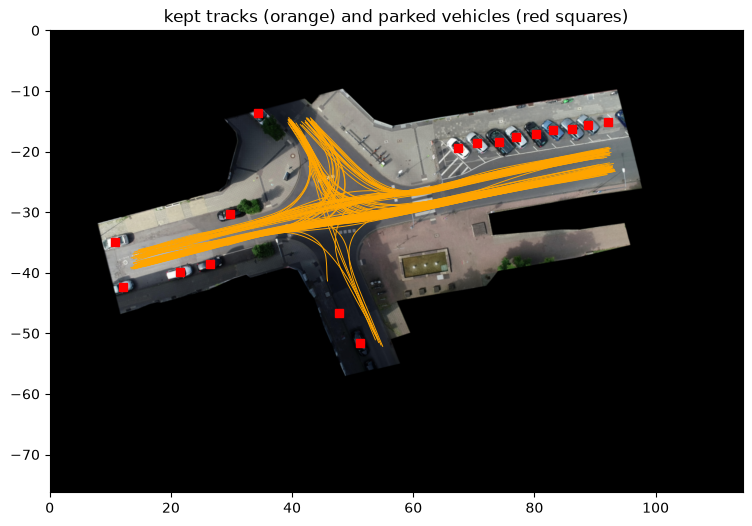

In [6]:
rec_meta = pd.read_csv(f"{DATA}18_recordingMeta.csv")
image = plt.imread(f"{DATA}18_background.png")
metres_per_pixel = rec_meta["orthoPxToMeter"][0] * 12
height, width = image.shape[:2]
extent = [0, width * metres_per_pixel, -height * metres_per_pixel, 0]

plt.figure(figsize=(9, 6))
plt.imshow(image, extent=extent)
for car in kept:
    plt.plot(car["xy"][:, 0], car["xy"][:, 1], color="orange", linewidth=0.7)
for xy in parked:
    plt.plot(xy[0, 0], xy[0, 1], "s", color="red")
plt.title("kept tracks (orange) and parked vehicles (red squares)")
plt.savefig("../figures/02_kept_and_parked.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
def cut_windows(car):
    windows = []
    xy = car["xy"]
    for start in range(0, len(xy) - (H + F) + 1, STRIDE):
        history = xy[start : start + H]                # 15 points
        future = xy[start + H : start + H + F]         # next 30 points
        yaw = car["heading"][start + H - 1]            # heading at the last history point
        windows.append({"history": history, "future": future, "yaw": yaw, "id": car["id"]})
    return windows

# pick the first car that has at least 4 windows and moves at least 30 m in its first 9 s
# (so the picture is not a car waiting at a red light)
for car in kept:
    if len(car["xy"]) >= 60 and np.linalg.norm(car["xy"][H + F - 1] - car["xy"][0]) > 30:
        break

windows = cut_windows(car)
print("this car has", len(car["xy"]), "points ->", len(windows), "windows")

this car has 61 points -> 4 windows


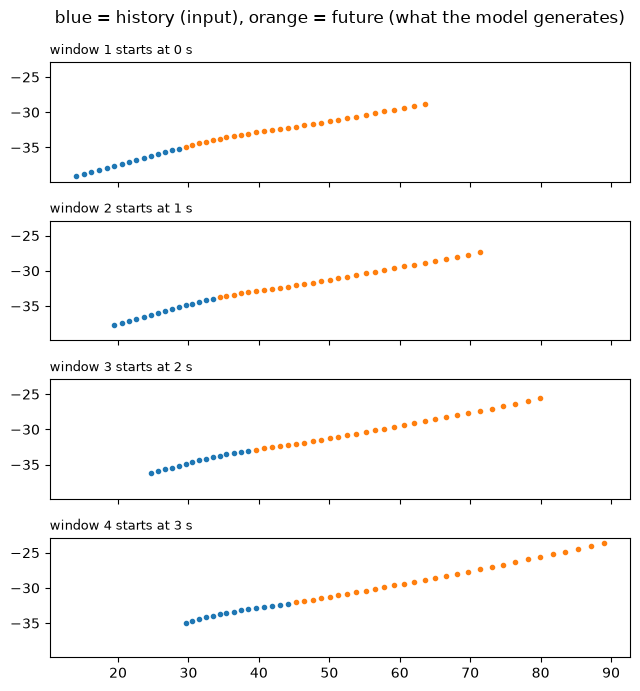

In [8]:
fig, axes = plt.subplots(4, 1, figsize=(9, 7), sharex=True, sharey=True)
for k in range(4):
    w = windows[k]
    axes[k].plot(w["history"][:, 0], w["history"][:, 1], "o", color="tab:blue", markersize=3)
    axes[k].plot(w["future"][:, 0], w["future"][:, 1], "o", color="tab:orange", markersize=3)
    axes[k].set_title(f"window {k + 1} starts at {k} s", fontsize=9, loc="left")
    axes[k].set_aspect("equal")
plt.suptitle("blue = history (input), orange = future (what the model generates)")
plt.tight_layout()
plt.savefig("../figures/02_windows.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
def to_vehicle_frame(points, origin, yaw):
    # move so the car is at (0, 0), then turn so the car faces +x
    shifted = points - origin
    c, s = np.cos(yaw), np.sin(yaw)
    x = c * shifted[:, 0] + s * shifted[:, 1]
    y = -s * shifted[:, 0] + c * shifted[:, 1]
    return np.stack([x, y], axis=1)

def to_map_frame(points, origin, yaw):
    # the opposite: turn back, then move back
    c, s = np.cos(yaw), np.sin(yaw)
    x = c * points[:, 0] - s * points[:, 1]
    y = s * points[:, 0] + c * points[:, 1]
    return np.stack([x, y], axis=1) + origin

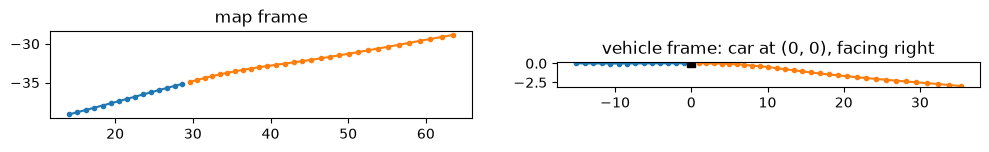

turning back gives the same points: True


In [10]:
w = windows[0]
origin = w["history"][-1]          # last history point
hist_v = to_vehicle_frame(w["history"], origin, w["yaw"])
fut_v = to_vehicle_frame(w["future"], origin, w["yaw"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(w["history"][:, 0], w["history"][:, 1], "o-", color="tab:blue", markersize=3)
axes[0].plot(w["future"][:, 0], w["future"][:, 1], "o-", color="tab:orange", markersize=3)
axes[0].set_title("map frame")
axes[1].plot(hist_v[:, 0], hist_v[:, 1], "o-", color="tab:blue", markersize=3)
axes[1].plot(fut_v[:, 0], fut_v[:, 1], "o-", color="tab:orange", markersize=3)
axes[1].plot(0, 0, "ks")
axes[1].set_title("vehicle frame: car at (0, 0), facing right")
for ax in axes:
    ax.set_aspect("equal")
plt.savefig("../figures/02_vehicle_frame.png", dpi=150, bbox_inches="tight")
plt.show()

back = to_map_frame(fut_v, origin, w["yaw"])
print("turning back gives the same points:", np.allclose(back, w["future"]))

In [11]:
def make_split(recordings):
    hist_map, fut_map, hist_veh, fut_veh, origins, yaws, recs, ids = [], [], [], [], [], [], [], []
    for rec in recordings:
        tracks, meta = load_recording(rec)
        vehicle_ids = meta[meta["class"].isin(["car", "truck_bus"])]["trackId"]
        vehicles = tracks[tracks["trackId"].isin(vehicle_ids)]
        vehicles = vehicles[vehicles["frame"] % KEEP_EVERY == 0]
        kept, parked, short = get_car_tracks(vehicles)
        count = 0
        for car in kept:
            for w in cut_windows(car):
                origin = w["history"][-1]
                hist_map.append(w["history"])
                fut_map.append(w["future"])
                hist_veh.append(to_vehicle_frame(w["history"], origin, w["yaw"]))
                fut_veh.append(to_vehicle_frame(w["future"], origin, w["yaw"]))
                origins.append(origin)
                yaws.append(w["yaw"])
                recs.append(rec)
                ids.append(w["id"])
                count += 1
        print(f"recording {rec}: {len(kept)} cars, {count} windows")
    return {
        "hist_map": np.array(hist_map, dtype=np.float32),   # (N, 15, 2)
        "fut_map": np.array(fut_map, dtype=np.float32),     # (N, 30, 2)
        "hist_veh": np.array(hist_veh, dtype=np.float32),   # (N, 15, 2)  <- model input
        "fut_veh": np.array(fut_veh, dtype=np.float32),     # (N, 30, 2)  <- the sample
        "origin": np.array(origins, dtype=np.float32),      # (N, 2)
        "yaw": np.array(yaws, dtype=np.float32),            # (N,)
        "rec": np.array(recs),
        "car_id": np.array(ids),
    }

for name, recordings in [("train", TRAIN), ("val", VAL), ("test", TEST)]:
    split = make_split(recordings)
    np.savez(f"{OUT}{name}.npz", **split)
    print(name, "->", len(split["fut_veh"]), "windows\n")

recording 18: 138 cars, 803 windows
recording 19: 109 cars, 734 windows
recording 20: 152 cars, 865 windows
recording 21: 167 cars, 1558 windows
recording 22: 177 cars, 1445 windows
recording 23: 149 cars, 1008 windows
recording 24: 111 cars, 1290 windows
recording 25: 185 cars, 1179 windows
train -> 8882 windows

recording 26: 199 cars, 1871 windows
recording 27: 166 cars, 1073 windows
val -> 2944 windows

recording 28: 175 cars, 1204 windows
recording 29: 191 cars, 1510 windows
test -> 2714 windows



In [13]:
train = np.load(f"{OUT}train.npz")
for name in train.files:
    print(name, train[name].shape)

hist_map (8882, 15, 2)
fut_map (8882, 30, 2)
hist_veh (8882, 15, 2)
fut_veh (8882, 30, 2)
origin (8882, 2)
yaw (8882,)
rec (8882,)
car_id (8882,)
